> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage5_lineage_and_evaluation_en.ipynb`)](../en/stage5_lineage_and_evaluation_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/05_stage5_lineage_and_eval_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage5)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → **[▶ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)**

---

# Stage 5. [검증 & 배포 게이트] End-to-End 데이터 리니지 · Golden CQ 감사 & Boundary 50회 벤치마크
## Step 5.1 원천 파일→청크→규칙→약정→CQ 엔드투엔드 리니지 검증 · Step 5.2 Golden CQ 5종 및 Boundary 10건×5회(50 Trials) 배포 게이트

Stage 5는 전체 엔지니어링 흐름의 최종 단계인 **Phase 8(검증 및 배포 게이트)**을 수행합니다. `stage5_resource_check`과 `src/lineage/lineage_engine.py` · `H.recheck_cq()`를 통해 **(1) 원천 CSV/가이드 파일 → SHA-256 청크 → 도메인 규칙(`W1~W3`) → 고객 약정 → Golden CQ 답변으로 이어지는 엔드투엔드 데이터 리니지**를 추적하고, **(2) 독립 검증 SQL(`verification_sql`) 대조 기반 Golden CQ 5종 전수 감사**, **(3) 경계 조건 10건 × 5회 반복(총 50 Trials) 안정성·일관성·의도 유지율 평가**, **(4) Gate 1 ~ Gate 5 프로덕션 배포 승인 판정**을 완결합니다.

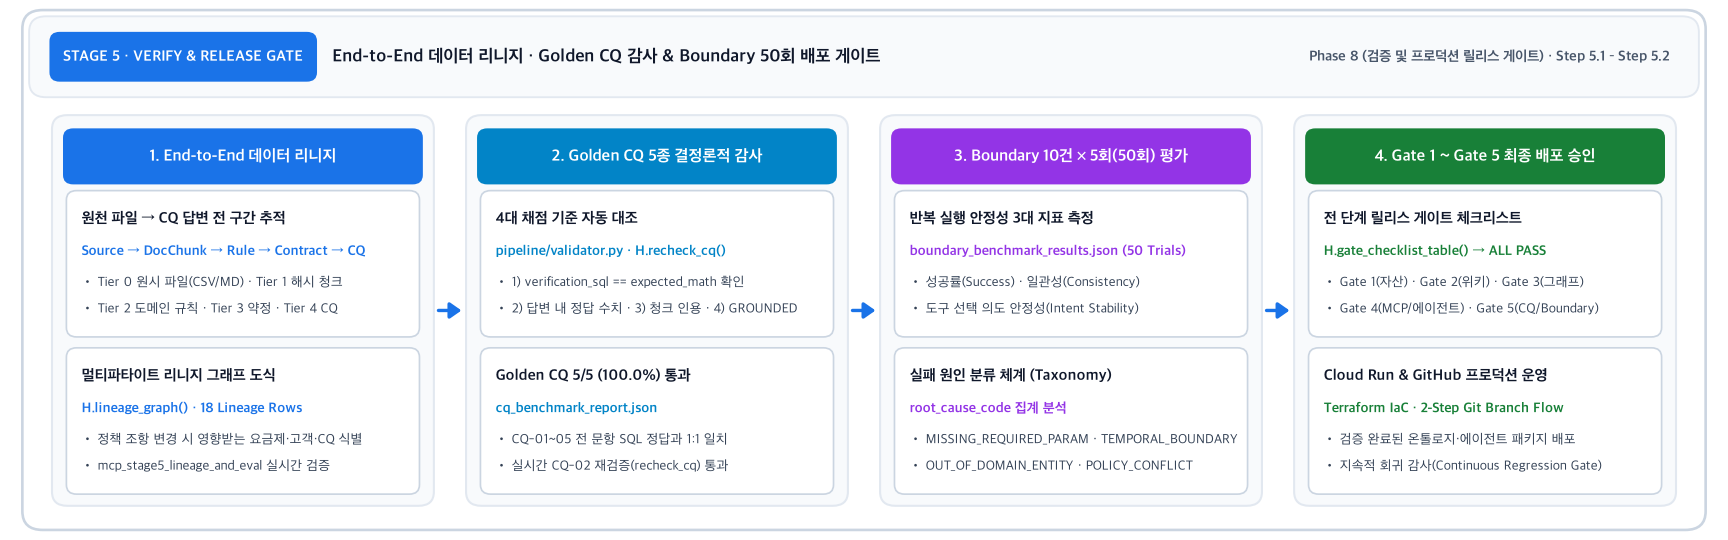


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 8a: 엔드투엔드 데이터 리니지 검증] `stage5_resource_check` 실행 · 리니지 조인(`%%bqsql`) · 멀티파타이트 리니지 설계 도식


In [ ]:
res_s5 = server.execute_tool("stage5_resource_check", {"steps": ["build_4tier_lineage", "run_golden_cq_suite", "diagnose_boundary_failures"]})
H.show_tool(res_s5)


In [ ]:
%%bqsql df_lineage
SELECT c.contract_id, c.customer_id, d.device_name, p.plan_name, s.policy_id,
       e.rule_id, e.source_chunk_id, ch.content_sha256 AS anchor, ch.source_file
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d ON d.device_id = c.device_id
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p ON p.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s ON s.device_id = c.device_id AND s.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e ON e.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = e.source_chunk_id
ORDER BY c.contract_id, e.rule_id


In [ ]:
H.show(df_lineage)
cq_rep = H.read_json("data/output/cq_benchmark_report.json")
lnodes, ledges = H.lineage_graph(H.pdf(df_lineage).to_dict("records"), cq_rep["test_results"])
H.draw_graph(lnodes, ledges,
             "End-to-End 데이터 리니지 멀티파타이트 그래프 (Source File → DocChunk → DomainRule → Contract → CQ)",
             layout="layers", figsize=(12, 6.0),
             legend={"Tier 0 Source File": "#5F6368", "Tier 1 DocChunk": "#9334E6", "Tier 2 DomainRule": "#F9AB00",
                     "Tier 3 Contract": "#1A73E8", "Tier 4 Golden CQ": "#188038"})


#### 스튜디오 리니지 DAG (`config/lineage_spec.json`) 실측
스튜디오 `Stage 5` 리니지와 같은 엔진(`src/lineage/lineage_engine.py`)입니다. 볼륨은 BigQuery `__TABLES__` 행 수, GCS 객체 수, `INFORMATION_SCHEMA.PROPERTY_GRAPHS` 노드·엣지 테이블 수를 지금 조회한 값이며, 실패하면 `lookup failed`로 남습니다.

**구조 원칙 (방법론)**: 정형 테이블은 테이블당 박스 1개, 엣지 테이블은 종류당 박스 1개로 그린다. 비정형 문서는 RAW → parsed → 재추출 게이트 → latest → 온톨로지 문서당 박스 1개로 흐르고, Wiki Agent 입력은 GCS의 온톨로지 latest다. 원격 MCP 서버 박스는 그리지 않는다.

**스타터 스펙**: 정형 테이블(`RAW_TB_*`)과 엣지 테이블(`TR_EDGE_*`)은 각각 박스 1개이고, 그래프 계층에 테이블별 노드 레이블 박스(`SEM_NODE_*`)가 따로 있다. 비정형 문서는 가이드 박스 2개 → 청커(`tb_doc_chunks`) → GCS `parsed/`와 위키 박스 1개(`gs://{bucket}/ontology/`)로 흐른다. 재추출 게이트, `latest` 승격, 온톨로지 문서별 박스, Wiki Agent 박스는 없고 원격 MCP 서버 박스도 없다.


In [ ]:
from src.lineage.lineage_engine import LineageEngine
lg = LineageEngine(str(H.ROOT / "config" / "lineage_spec.json"), {
    "project_id": server.project_id, "fq": server.fq, "dataset_id": server.fq.split(".", 1)[1],
    "bucket": server.gcs_bucket, "model": agent.model_name,
    "spanner_instance": server.spanner_instance_id, "spanner_database": server.spanner_database_id}).build_graph()
H.md(f"**nodes `{lg['stats']['total_nodes']}` · edges `{lg['stats']['total_edges']}` · categories `{lg['stats']['total_categories']}` · "
     f"measured `{lg['metadata']['live_nodes']}/{lg['metadata']['bq_nodes']}` · errors `{lg['metadata']['bq_error'] or 0}`**")
H.show(pd.DataFrame([{"category": n["cat"], "node": n["id"], "volume": n["volume_en"], "measured": n["live"], "source": n["live_src"]}
                     for n in lg["nodes"] if n["live_src"]]))


### 2. [Phase 8b: Golden CQ 5종 정량 감사 (`H.recheck_cq`)] 벤치마크 리포트 분석 및 실시간 에이전트 4대 채점 조건 재검증


#### 평가 표시 순서: A 전체 결과 → B CQ별 검증 → C 루브릭 기준
A는 통과 수, 루브릭 평균, 감점 CQ 수, 축별 평균이다. B는 CQ마다 기대값과 검증 SQL 결과, 점수·판정·감점 수, 근거(인용 청크, 검증 job ID, 에이전트 BigQuery job 수, 심사 요약)와 실제 답변 발췌다. C는 루브릭 축 정의다. 값은 모두 `data/output/cq_benchmark_report.json`에서 읽는다. 스타터 리포트의 루브릭 설명은 영문만 있다(`name_ko`, `desc_ko`, `judge_instructions_ko` 필드 없음). 답변 원문은 한국어로 저장되어 있어 영문 노트북은 답변 발췌 대신 심사 요약만 보여준다. 마지막으로 `CQ-02`를 지금 다시 실행해 채점 조건을 확인한다.


In [ ]:
df_cq = pd.DataFrame(cq_rep["test_results"])
H.md("#### A. 전체 결과")
H.md(f"**Golden CQ Benchmark `{cq_rep['benchmark_id']}`** · Evaluated `{cq_rep['evaluated_at']}` · Model `{cq_rep['model']}` · Passed **`{cq_rep['passed']}/{cq_rep['total_cqs']} ({cq_rep['accuracy_rate']}%)`** · "
     f"Rubric avg `{cq_rep['rubric_avg_total']}` · CQs with deductions `{sum(1 for r in cq_rep['test_results'] if r['rubric']['deductions'])}` · LLM tokens `{cq_rep['llm_tokens_total']:,}`")
H.show(pd.DataFrame([cq_rep["rubric_axis_avg"]]))

H.md("#### B. CQ별 검증 (점수 · 근거 · 실제 답변)")
df_cq["score"] = df_cq["rubric"].map(lambda r: r["scores"]["total"])
df_cq["verdict"] = df_cq["rubric"].map(lambda r: r["verdict"])
df_cq["deductions"] = df_cq["rubric"].map(lambda r: len(r["deductions"]))
df_cq["judge_summary"] = df_cq["rubric"].map(lambda r: r["summary"])
df_cq["agent_bq_jobs"] = df_cq["agent_bq_job_ids"].map(len)
H.show(df_cq, ["cq_id", "status", "expected_math", "verification_sql_result", "verification_job_id", "score", "verdict", "deductions",
               "grounded_chunk", "agent_bq_jobs", "llm_tokens", "elapsed_s", "judge_summary"])
for r in cq_rep["test_results"]:
    H.md(f"**{r['cq_id']}** · {r['query']}\n\n" + "\n".join("> " + ln.lstrip("# ") if ln.strip() else ">" for ln in r["answer_excerpt"].splitlines()[:10]))
H.bar(df_cq, "cq_id", "elapsed_s", "Golden CQ별 에이전트 2-Pass 응답 소요 시간 (초)", fmt="{:.2f}")

H.md("#### C. 루브릭 기준")
H.show(pd.DataFrame(cq_rep["rubric"]))

cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
res_cq2, df_chk = H.recheck_cq(cqs[1], agent)
H.show_agent(res_cq2, title="실시간 재검증 (Live Re-Audit): CQ-02")
H.show(df_chk)


### 3. [Phase 8c: Boundary 10건 × 5회 반복(50 Trials) 안정성 평가 & Gate 1~5 배포 승인 판정]


In [ ]:
b_rep = H.read_json("data/output/boundary_benchmark_results.json")
df_bc = pd.DataFrame(b_rep["cases"])
H.md(f"**Boundary Benchmark `{b_rep['benchmark_id']}`** · Trials=`{b_rep['total_trials']}` · "
     f"avg_success_rate=`{b_rep['avg_success_rate']}%` · avg_consistency_rate=`{b_rep['avg_consistency_rate']}%` · "
     f"avg_intent_stability=`{b_rep['avg_intent_stability']}%`")
H.show(df_bc, ["case_id", "root_cause_code", "missing_context", "trials", "passed_trials", "success_rate", "consistency_rate", "intent_stability"])
H.grouped_bar(df_bc, "case_id", ["success_rate", "consistency_rate", "intent_stability"],
              "Boundary 10건 × 5회 반복 평가 지표 비교 (%)")
df_tax = df_bc.groupby("root_cause_code", as_index=False).agg(
    cases=("case_id", "count"), avg_success=("success_rate", "mean"),
    avg_consistency=("consistency_rate", "mean"), avg_intent_stability=("intent_stability", "mean"))
H.show(df_tax)
H.md("#### Gate 1 ~ Gate 5 프로덕션 배포 준비 완료 최종 판정표")
H.show(H.gate_checklist_table())


### Q&A
- **Q.** Golden CQ 감사(`H.recheck_cq`)는 에이전트 답변의 정확성과 환각 부재를 어떤 기준으로 채점하나요?
  - **A.** 각 Golden CQ마다 (1) BigQuery에서 독립 실행한 `verification_sql` 결과가 `expected_math`와 일치하는지, (2) 에이전트 답변 본문에 정답 수치가 포함(`_has` 정규식)되는지, (3) 지정된 `DOC_CHUNK`를 인용했는지, (4) `answer_status == GROUNDED`인지 확인하고, (5) 최종 답변을 LLM 루브릭으로 채점합니다.

### Data Analysis Key Findings
- 엔드투엔드 데이터 리니지 조인(`df_lineage`, 18행)을 통해 원천 파일(`sample_policy_guide.md`, `sample_welfare_exemption_guide.md`, `customer_contracts.csv`, `domain_rules.csv`)부터 `DOC_CHUNK_001~005`, `RULE_*` 4종, 고객 약정 6건, `CQ-01~05`까지의 전 구간 추적성이 확인되었습니다.
- Golden CQ 리포트(2026-09-30): 5/5 통과(`100.0%`), 루브릭 평균 `100.0`. `CQ-02` 실시간 재검증 결과는 위 표를 따릅니다. 스타터 CQ는 단일 값 질문이라 만점이 나오기 쉽습니다.
- Boundary 리포트(2026-09-27, 50 Trials): 평균 성공률 `96.0%`, 응답 일관성 `92.0%`, 의도 안정성 `78.0%`. Gate 1 ~ Gate 5 판정은 위 판정표를 따릅니다.

### Insights or Next Steps
- 5-Stage 에이전틱 온톨로지 전 과정 워크스루를 완료했습니다! 상단 또는 하단 링크를 통해 `0. 전체 흐름 초기 화면`이나 각 Stage 노트북(한/영)으로 자유롭게 이동하거나, 자체 도메인 CSV/가이드 데이터를 `data/input/`에 적용해 보세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [🌐 English Version](../en/stage5_lineage_and_evaluation_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/05_stage5_lineage_and_eval_ko.md)
